Step 1: Imports and load the data

In [79]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_openml

sns.set_theme(style="whitegrid")

df = fetch_openml(name="house_prices", as_frame=True, parser="auto").frame
for c in df.select_dtypes(include="category").columns:
    df[c] = df[c].astype("object")

print(df.shape)                       # about (1460, 81)
print("SalePrice" in df.columns)      # must be True
df.head()

(1460, 81)
True


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Step 2: Missing values

In [80]:
missing = df.isnull().sum().sort_values(ascending=False)
miss_df = pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})
display(miss_df[miss_df.missing > 0])

,missing,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageFinish,81,5.55
GarageQual,81,5.55
GarageYrBlt,81,5.55
GarageType,81,5.55


Step 3: Variable types

In [81]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

qual_order = ["Po", "Fa", "TA", "Gd", "Ex"]
for col in ["ExterQual", "KitchenQual"]:
    df[col] = pd.Categorical(df[col], categories=qual_order, ordered=True)

print("Numeric:", len(numeric_cols), "| Categorical:", len(categorical_cols))

Numeric: 38 | Categorical: 43


Step 4: Descriptive statistics

In [82]:
display(df[numeric_cols].describe().T)

for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col]
    print(f"\n{col}: mean {s.mean():.0f} | median {s.median():.0f} | std {s.std():.0f}")
    print(f"skew {s.skew():.2f} | kurtosis {s.kurt():.2f}")

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



SalePrice: mean 180921 | median 163000 | std 79443
skew 1.88 | kurtosis 6.54

GrLivArea: mean 1515 | median 1464 | std 525
skew 1.37 | kurtosis 4.90

LotArea: mean 10517 | median 9478 | std 9981
skew 12.21 | kurtosis 203.24


Step 5: Distributions

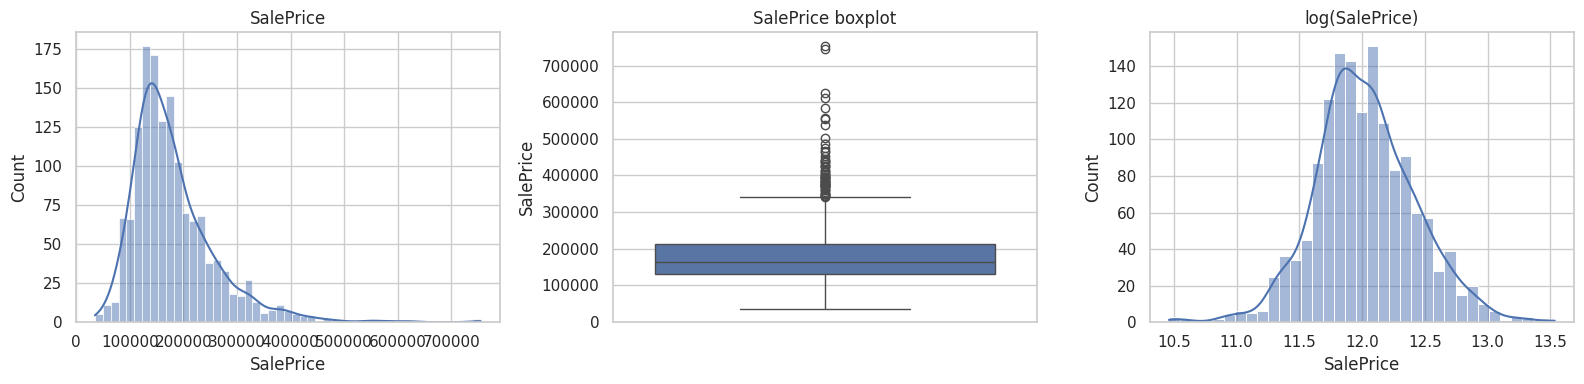

Skew before log: 1.8828757597682129 | after: 0.12133506220520406


In [83]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["SalePrice"], kde=True, ax=ax[0]); ax[0].set_title("SalePrice")
sns.boxplot(y=df["SalePrice"], ax=ax[1]); ax[1].set_title("SalePrice boxplot")
sns.histplot(np.log(df["SalePrice"]), kde=True, ax=ax[2]); ax[2].set_title("log(SalePrice)")
plt.tight_layout(); plt.show()
print("Skew before log:", df["SalePrice"].skew(), "| after:", np.log(df["SalePrice"]).skew())

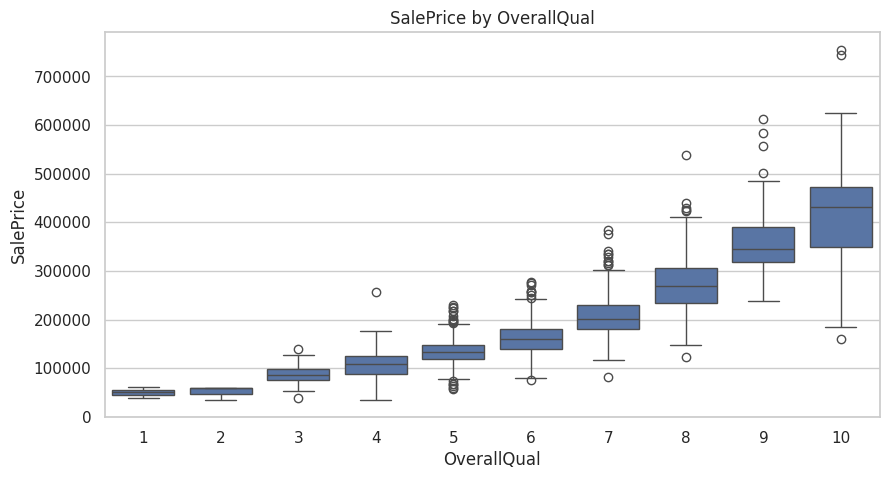

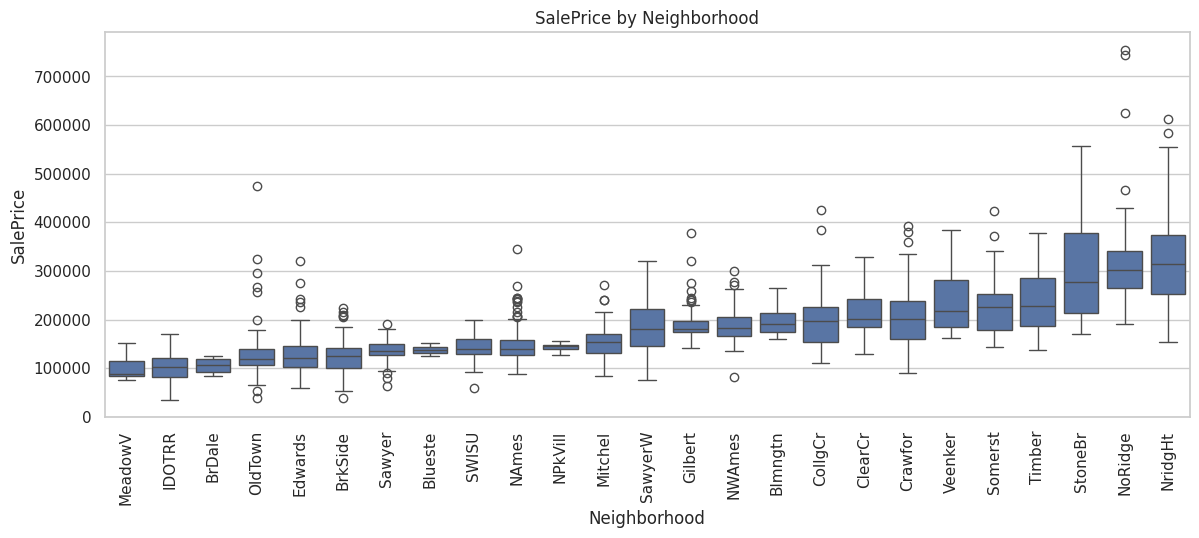

In [84]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="OverallQual", y="SalePrice", data=df)
plt.title("SalePrice by OverallQual"); plt.show()

order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 5))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order)
plt.xticks(rotation=90); plt.title("SalePrice by Neighborhood"); plt.show()

Step 6: Correlation

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


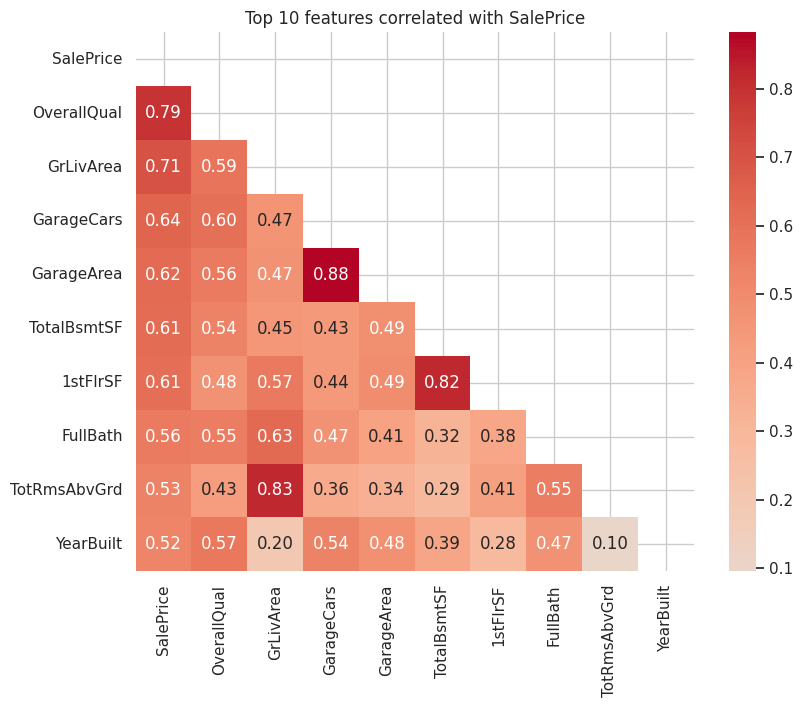

In [85]:
num = df.select_dtypes(include="number")
corr_matrix = num.corr()
cov_matrix = num.cov()

top = corr_matrix["SalePrice"].abs().sort_values(ascending=False)
print(top.head(11))

top10 = top.head(10).index
mask = np.triu(np.ones((10, 10), dtype=bool))
plt.figure(figsize=(9, 7))
sns.heatmap(df[top10].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask)
plt.title("Top 10 features correlated with SalePrice"); plt.show()

Step 7: Scatter plots

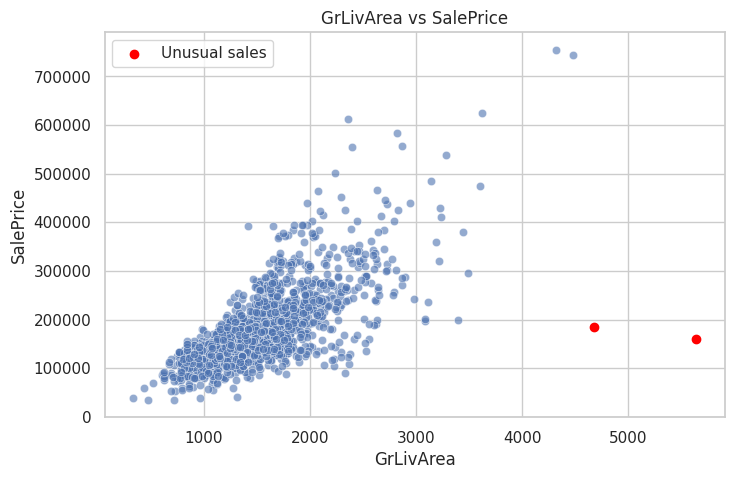

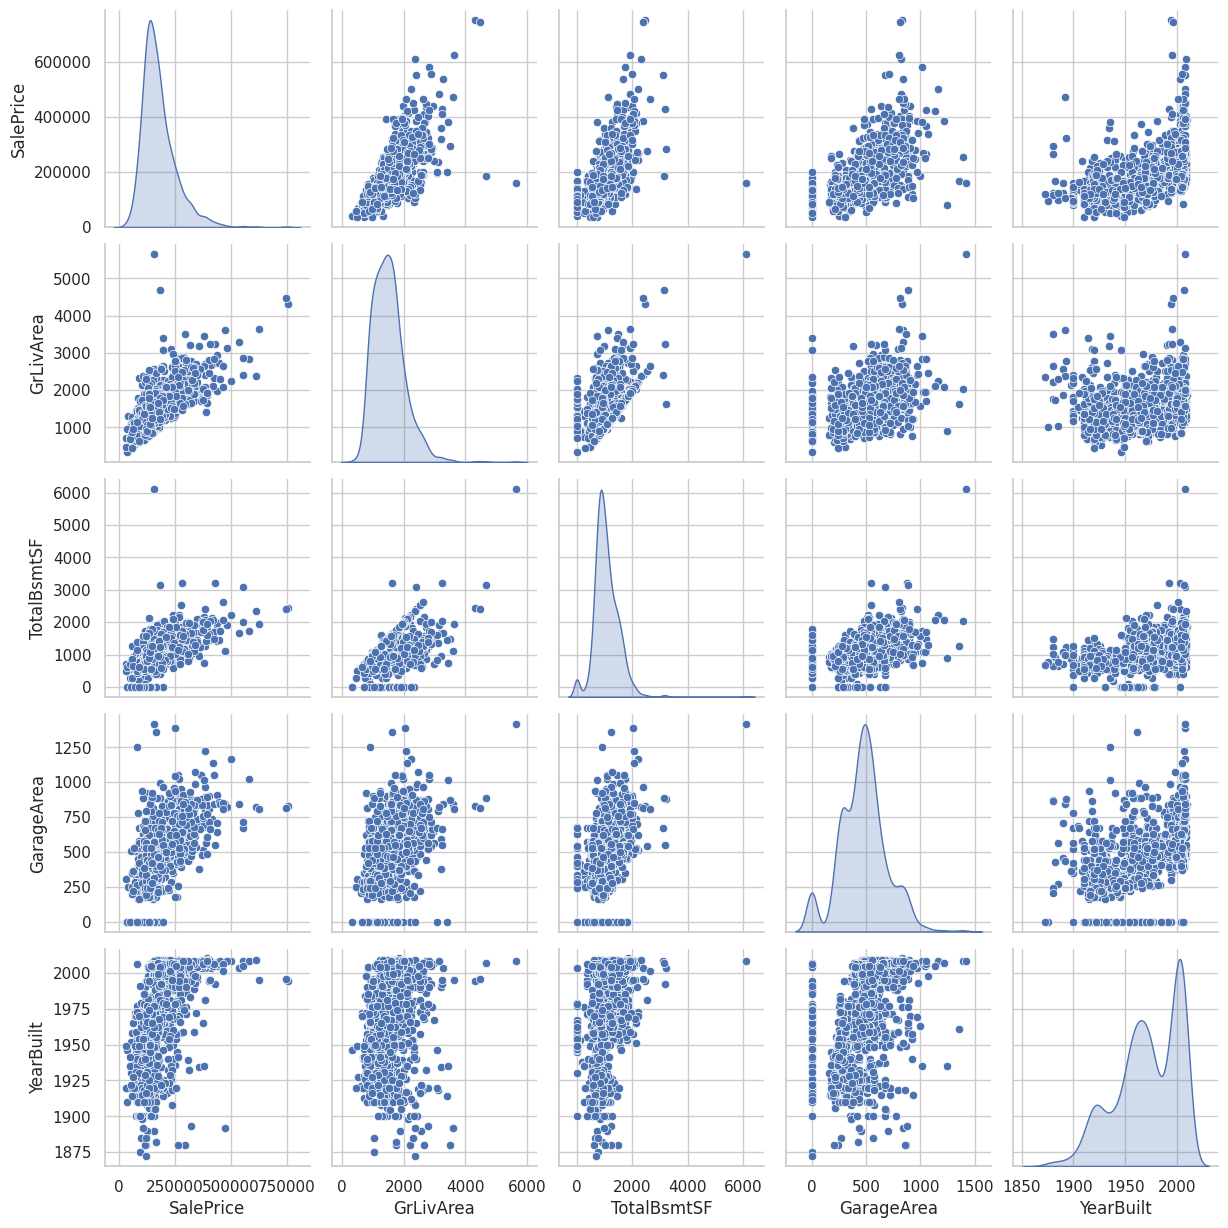

In [86]:
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df, alpha=.6)
odd = df[(df.GrLivArea > 4000) & (df.SalePrice < 300000)]
plt.scatter(odd.GrLivArea, odd.SalePrice, color="red", label="Unusual sales")
plt.title("GrLivArea vs SalePrice"); plt.legend(); plt.show()

sns.pairplot(df[["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]], diag_kind="kde")
plt.show()

Step 8: Outliers

In [87]:
def iqr_outliers(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    i = q3 - q1
    return s[(s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)]

def zscore_outliers(s, t=3):
    return s[((s - s.mean()) / s.std()).abs() > t]

for col in ["GrLivArea", "SalePrice"]:
    a, b = iqr_outliers(df[col]), zscore_outliers(df[col])
    print(col, "| IQR:", len(a), "| z-score:", len(b), "| overlap:", len(set(a.index) & set(b.index)))

df_clean = df.drop(df[(df.GrLivArea > 4000) & (df.SalePrice < 300000)].index)
print(df.shape, "->", df_clean.shape)

GrLivArea | IQR: 31 | z-score: 16 | overlap: 16
SalePrice | IQR: 61 | z-score: 22 | overlap: 22
(1460, 81) -> (1458, 81)


Step 9: Data cleaning

In [88]:
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "GarageType",
             "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond",
             "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "MasVnrType"]
for col in none_cols:
    df_clean[col] = df_clean[col].fillna("None")

df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(lambda x: x.fillna(x.median()))
df_clean["MasVnrArea"] = df_clean["MasVnrArea"].fillna(0)
df_clean["GarageYrBlt"] = df_clean["GarageYrBlt"].fillna(0)

left = df_clean.isnull().sum()
print(left[left > 0])
print("Duplicates:", df_clean.duplicated().sum())

Electrical    1
dtype: int64
Duplicates: 0


Step 10: Dashboard

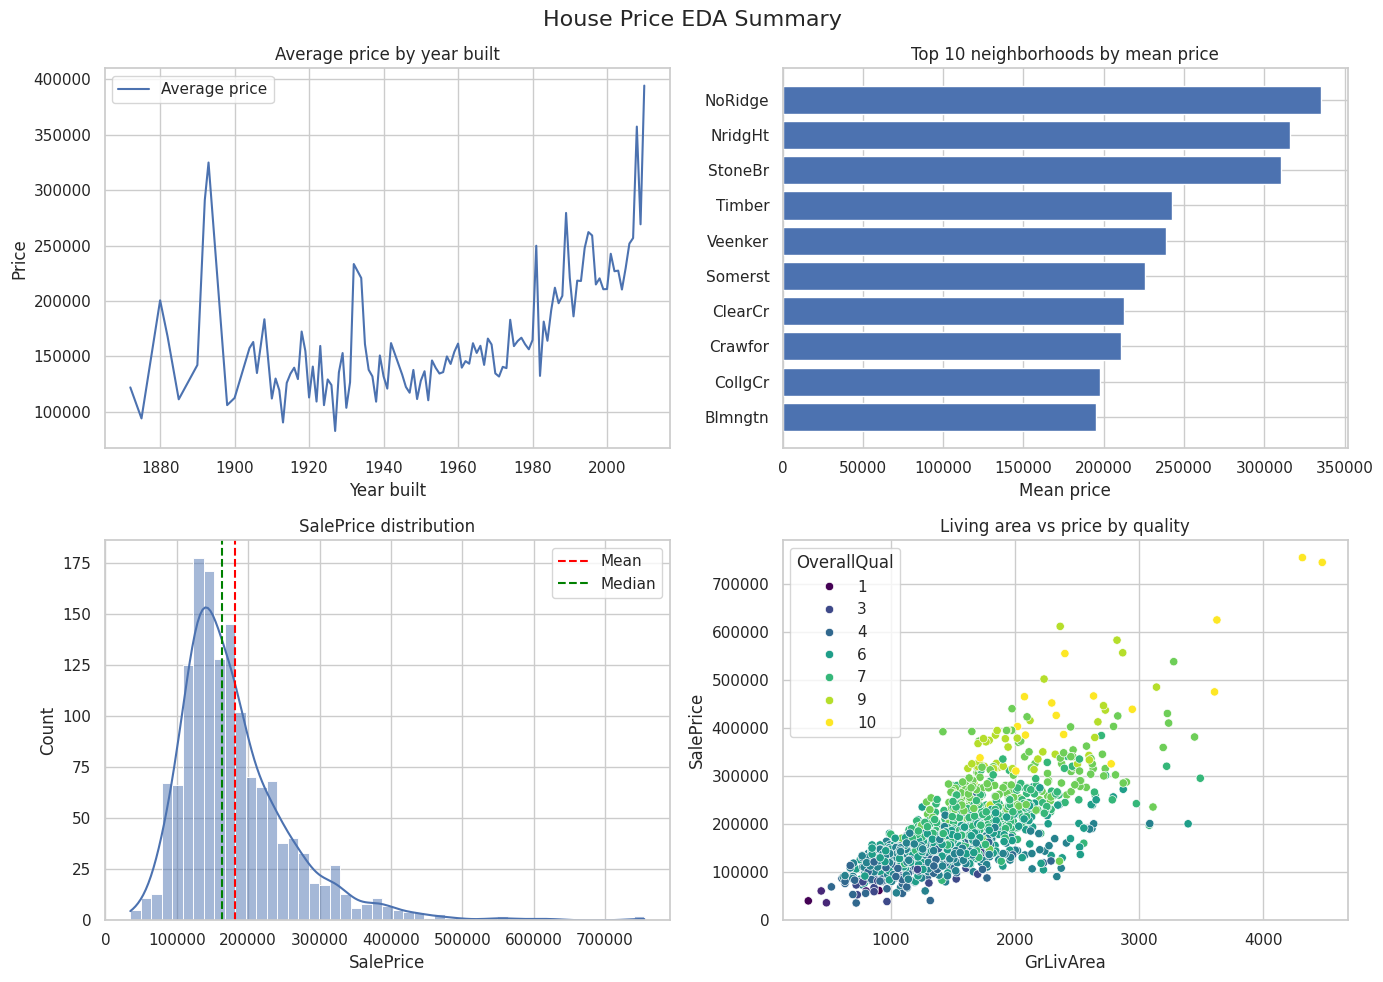

In [89]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

yr = df_clean.groupby("YearBuilt")["SalePrice"].mean()
ax[0, 0].plot(yr.index, yr.values, label="Average price")
ax[0, 0].set(title="Average price by year built", xlabel="Year built", ylabel="Price"); ax[0, 0].legend()

topn = df_clean.groupby("Neighborhood")["SalePrice"].mean().sort_values().tail(10)
ax[0, 1].barh(topn.index, topn.values)
ax[0, 1].set(title="Top 10 neighborhoods by mean price", xlabel="Mean price")

sns.histplot(df_clean["SalePrice"], kde=True, ax=ax[1, 0])
ax[1, 0].axvline(df_clean.SalePrice.mean(), color="red", ls="--", label="Mean")
ax[1, 0].axvline(df_clean.SalePrice.median(), color="green", ls="--", label="Median")
ax[1, 0].set_title("SalePrice distribution"); ax[1, 0].legend()

sns.scatterplot(x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", data=df_clean, ax=ax[1, 1])
ax[1, 1].set_title("Living area vs price by quality")

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()